# Paramagnetic comparison with NFL_REWORKED

This notebook mirrors the existing paramagnetic `mu`, `S`, and `n(k)` comparisons, but adds `NFL_REWORKED` as an extra curve without modifying the original notebooks.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")

import qss
from qss.chemical_potential import chemical_potential
from qss.distributions import DistType, prepare_2D_lattice_data
from qss.entropy import entropy
from qss.solver_options import brent_defaults
import tools.scientific_plot_v2 as sp

print("python:", sys.executable)
print("cwd:", Path.cwd())
print("qss:", qss.__file__)
print("distros:", [member.name for member in DistType])

plotter = sp.ScientificPlotter(config=sp.PlotConfig(legend_loc="center left"))


python: /home/piotr/Documents/github/quantum-statistics-solver_workingcopy/.venv/bin/python
cwd: /home/piotr/Documents/github/quantum-statistics-solver/notebooks/Graphs
qss: /home/piotr/Documents/github/quantum-statistics-solver_workingcopy/.venv/lib/python3.11/site-packages/qss/__init__.py
distros: ['FD', 'FLB', 'NFL', 'NFL_REWORKED', 'NFLB', 'SSL', 'HUBBARD']


In [2]:
N = 100
kx = np.linspace(-np.pi, np.pi, N)
ky = np.linspace(-np.pi, np.pi, N)
t_prim=0.0
e_k, _, _ = prepare_2D_lattice_data(kx, ky, t=-1.0, t_prim=0.25)

U = 100.0
H_a = np.array([0.0], dtype=np.float64)
kBT_mu = np.array([10.0, 1.0, 0.01], dtype=np.float64)
n_mu = np.linspace(0.01, 0.99, 40, dtype=np.float64)

distros = [
    DistType.FD,
    DistType.FLB,
    DistType.NFL,
    DistType.NFL_REWORKED,
    DistType.NFLB,
    DistType.SSL,
    DistType.HUBBARD,
]
distro_names = [d.name for d in distros]

solver_opts = brent_defaults(
    abs_tol=1e-9,
    rel_tol=1e-6,
    expand_factor=2.0,
    initial_step=1.0,
    max_expands=164,
    max_iters=5000,
).to_qss()


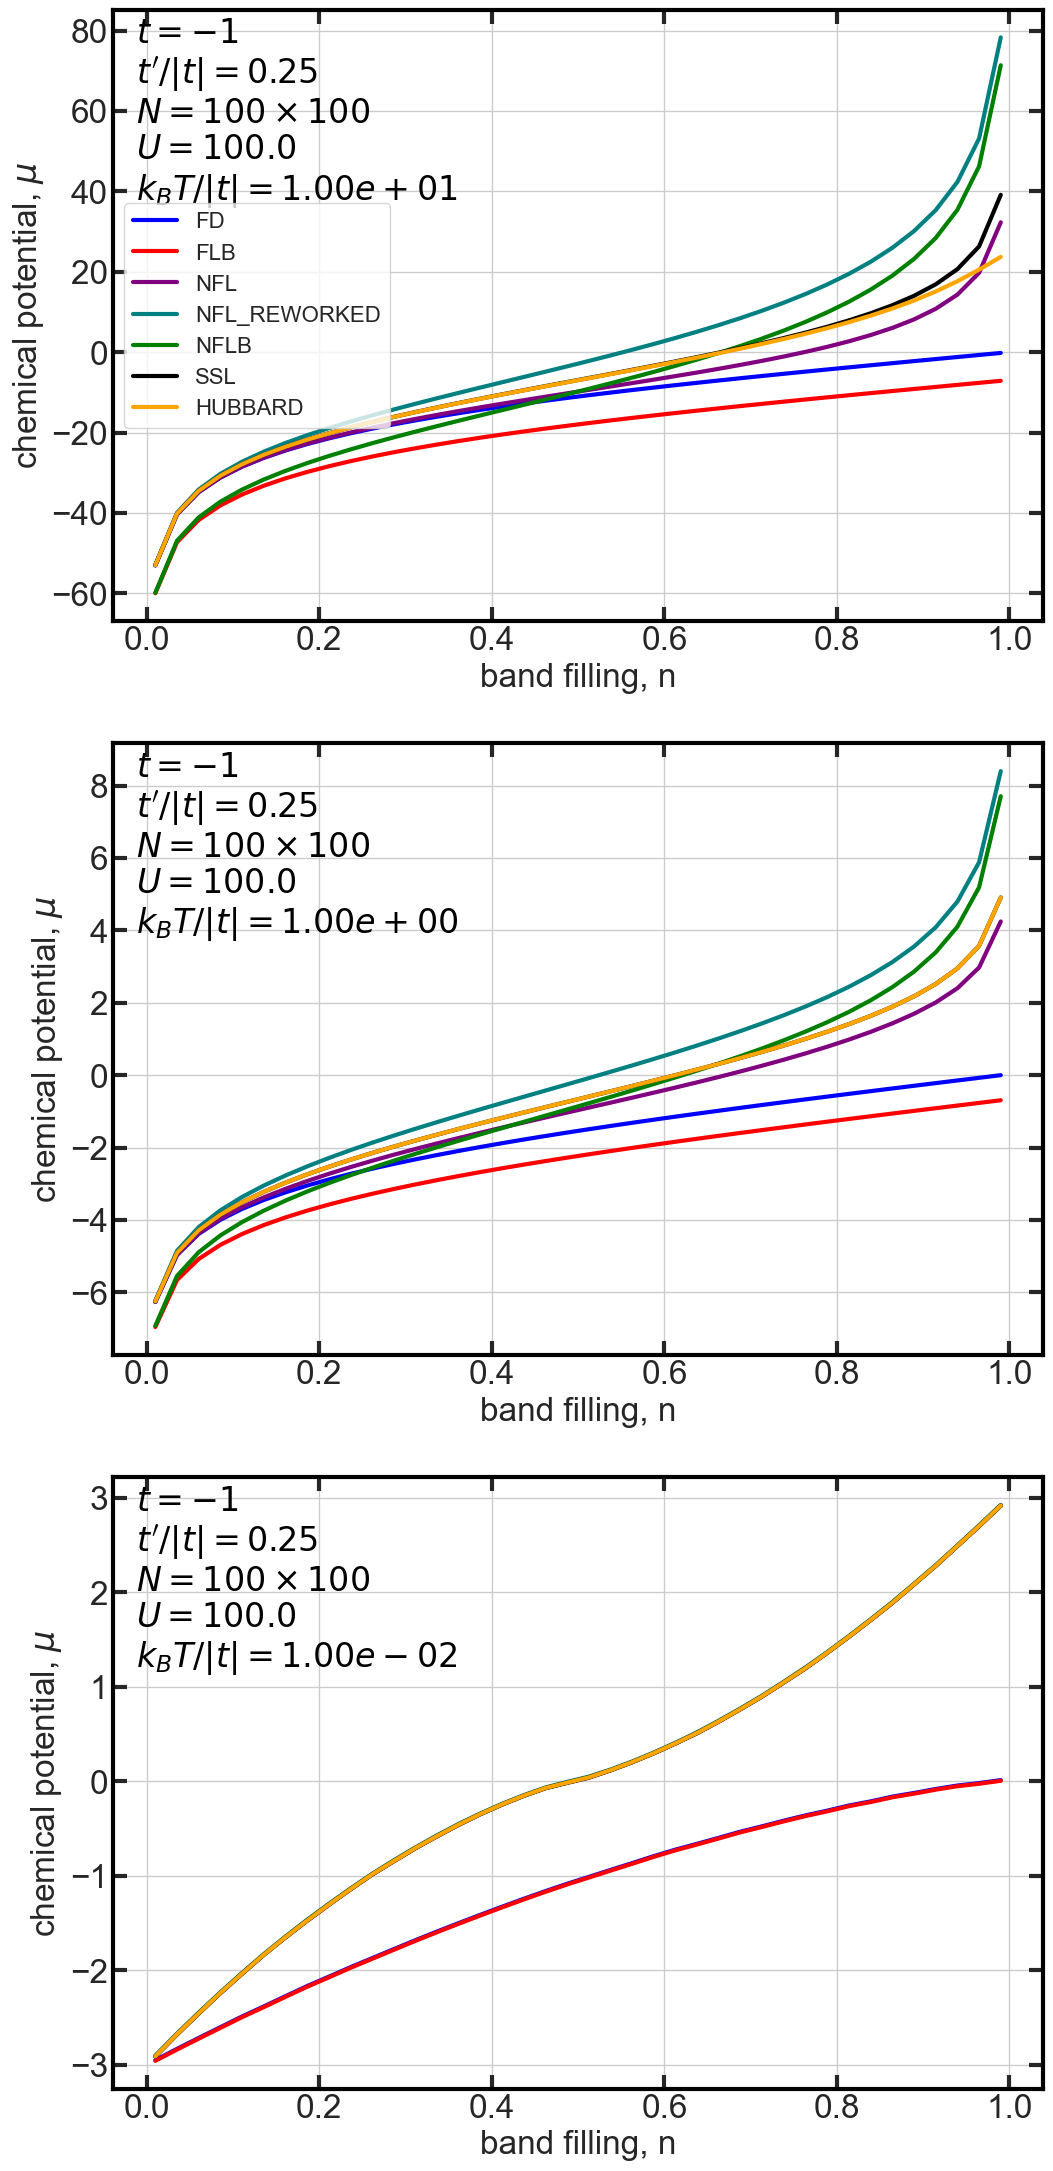

In [3]:
mu_df = chemical_potential(
    distros=distros,
    n_vals=n_mu,
    kBT_vals=kBT_mu,
    H_a_vals=H_a,
    N=N,
    E=e_k,
    U=U,
    solver_opts=solver_opts,
    x0=-1.0,
    a0=-5.0,
    b0=5.0,
)

plotter.plot_scalar_result(
    results=mu_df,
    x_param="n",
    y_col="mu",
    y_label=r"chemical potential, $\mu$",
    fixed_params={"H_a": H_a[0]},
    distros=distro_names,
    subplots_param="kBT",
    subplots_vals=kBT_mu,
    cols=1,
    U=U,
    figsize=(12, 9),
)
plt.show()


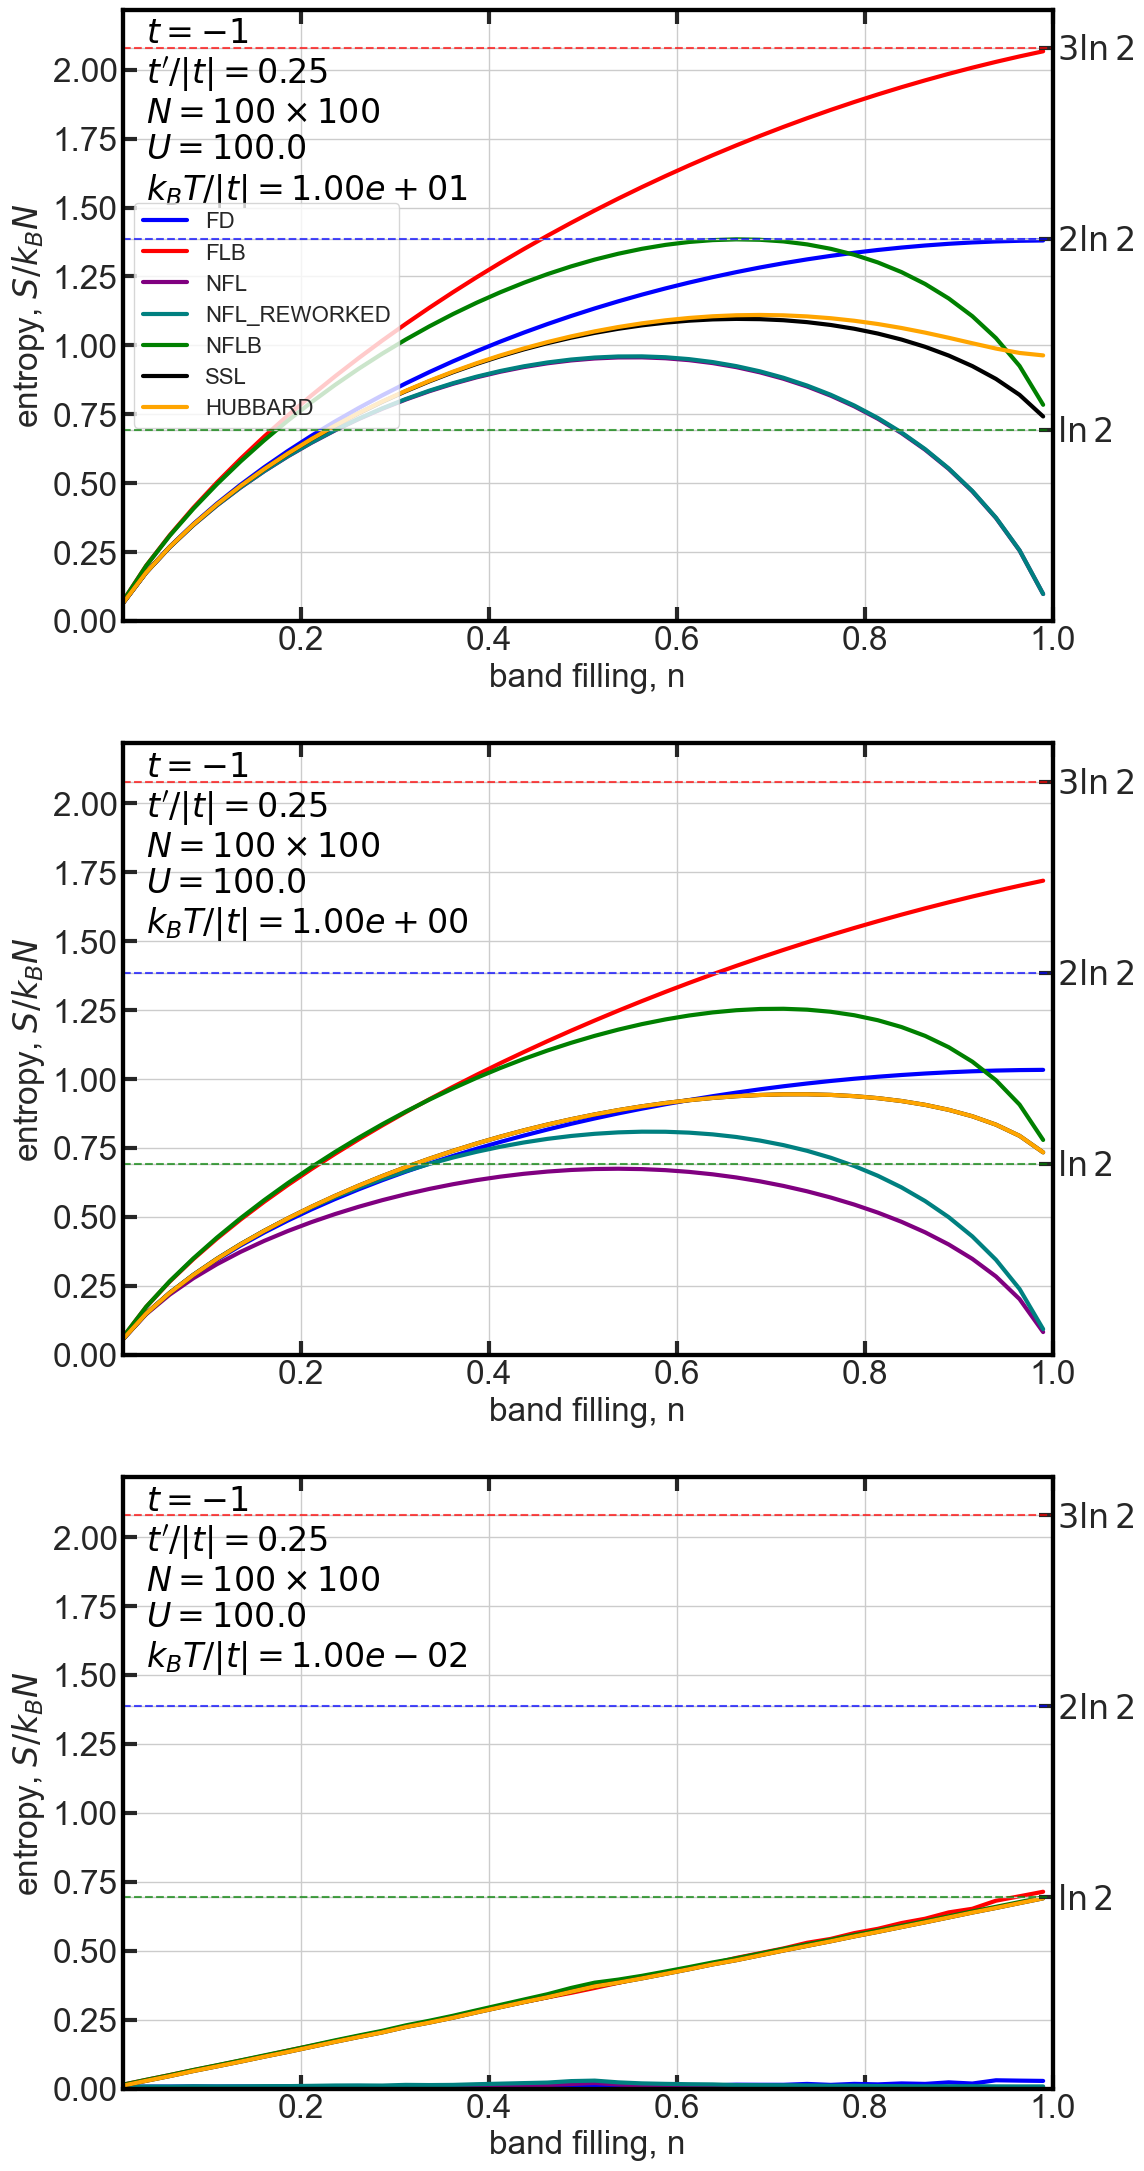

In [4]:
entropy_df = entropy(df=mu_df, E=e_k, U=U)

plotter.plot_scalar_result(
    results=entropy_df,
    x_param="n",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"H_a": H_a[0]},
    distros=distro_names,
    subplots_param="kBT",
    subplots_vals=kBT_mu,
    cols=1,
    U=U,
    figsize=(12, 9),
    show_log_vals=True,
    ylims=(0, 2.6),
    xlims=(0.01, 1.0),
)
plt.show()


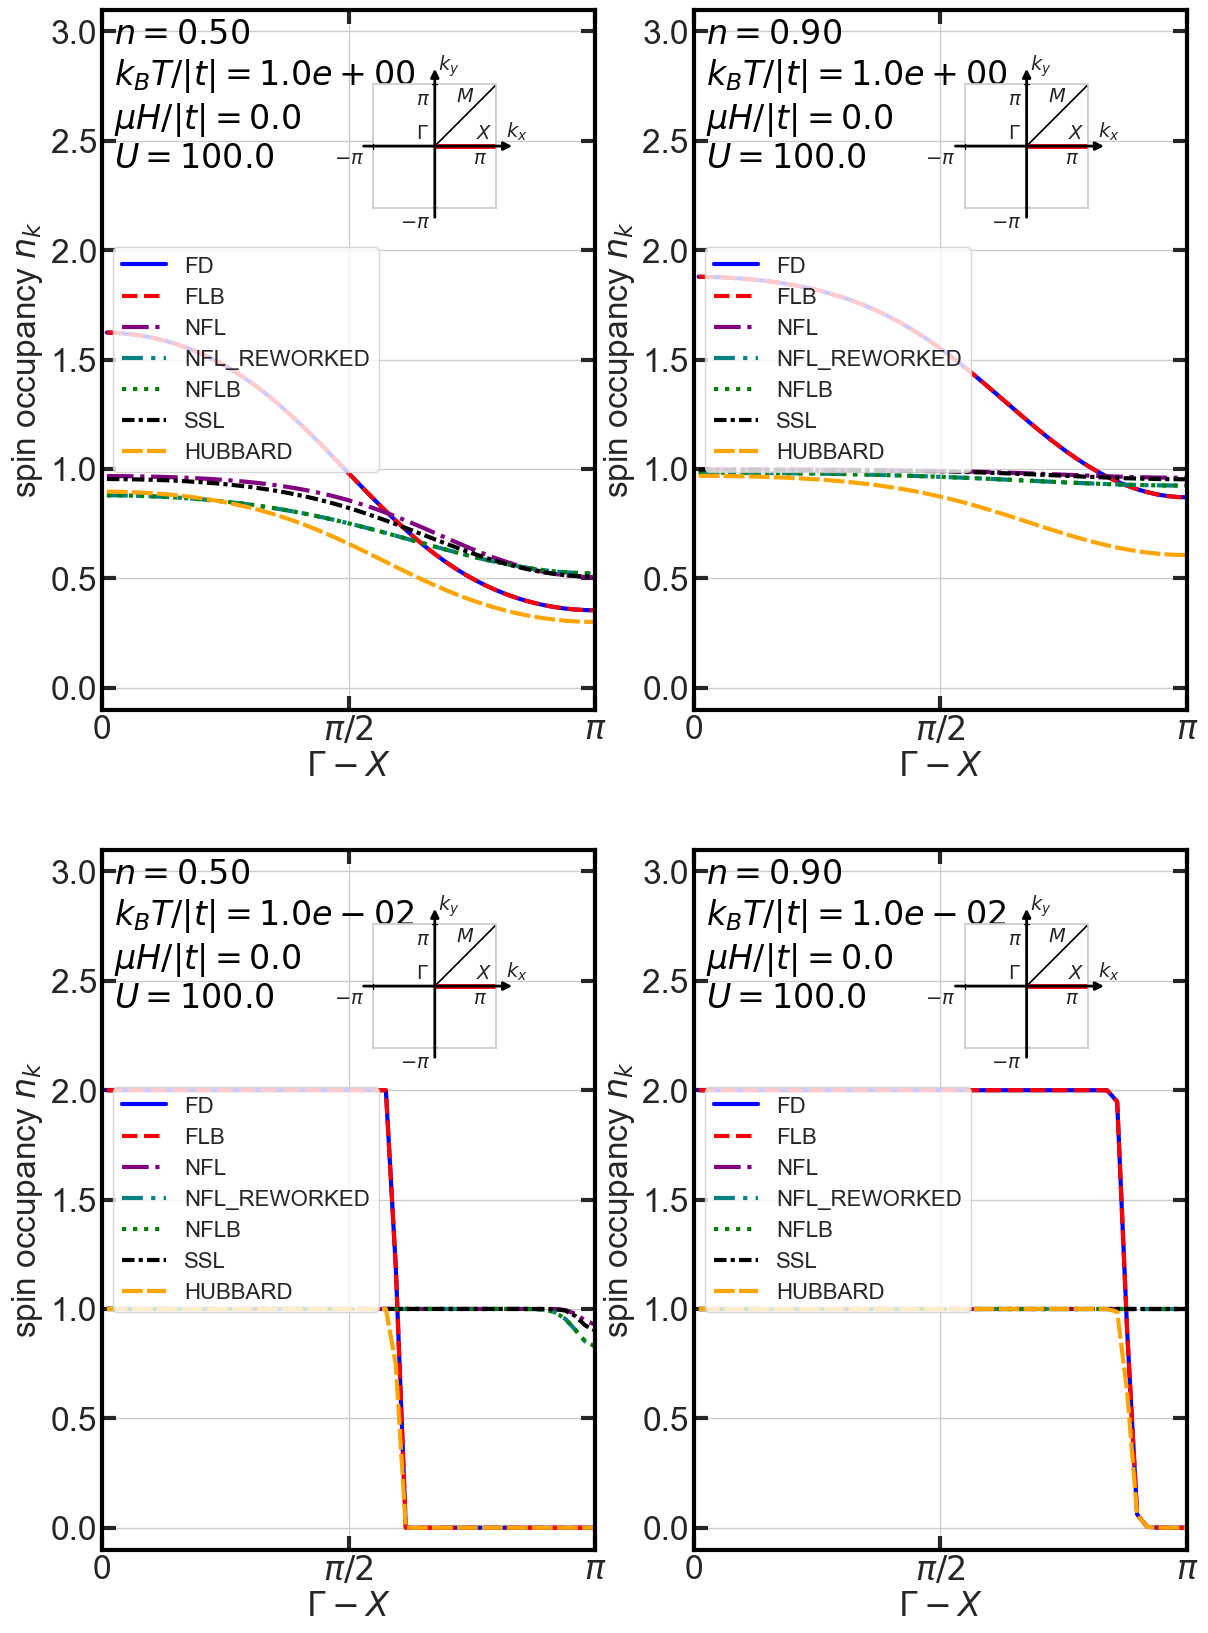

In [5]:
n_plot = np.array([0.5, 0.9], dtype=np.float64)
kBT_plot = np.array([1.0, 0.01], dtype=np.float64)

plotter.plot_energy_distribution_1d(
    e_k=e_k,
    slice_type="horizontal",
    dim=2,
    kx=kx,
    n=n_plot,
    kBTs=kBT_plot,
    H=H_a[0],
    U=U,
    distributions=distro_names,
    figsize=(14, 10),
    ylims=(-0.1, 3.1),
    bz_inset_pos=(0.55, 0.68, 0.25, 0.25),
)
plt.show()


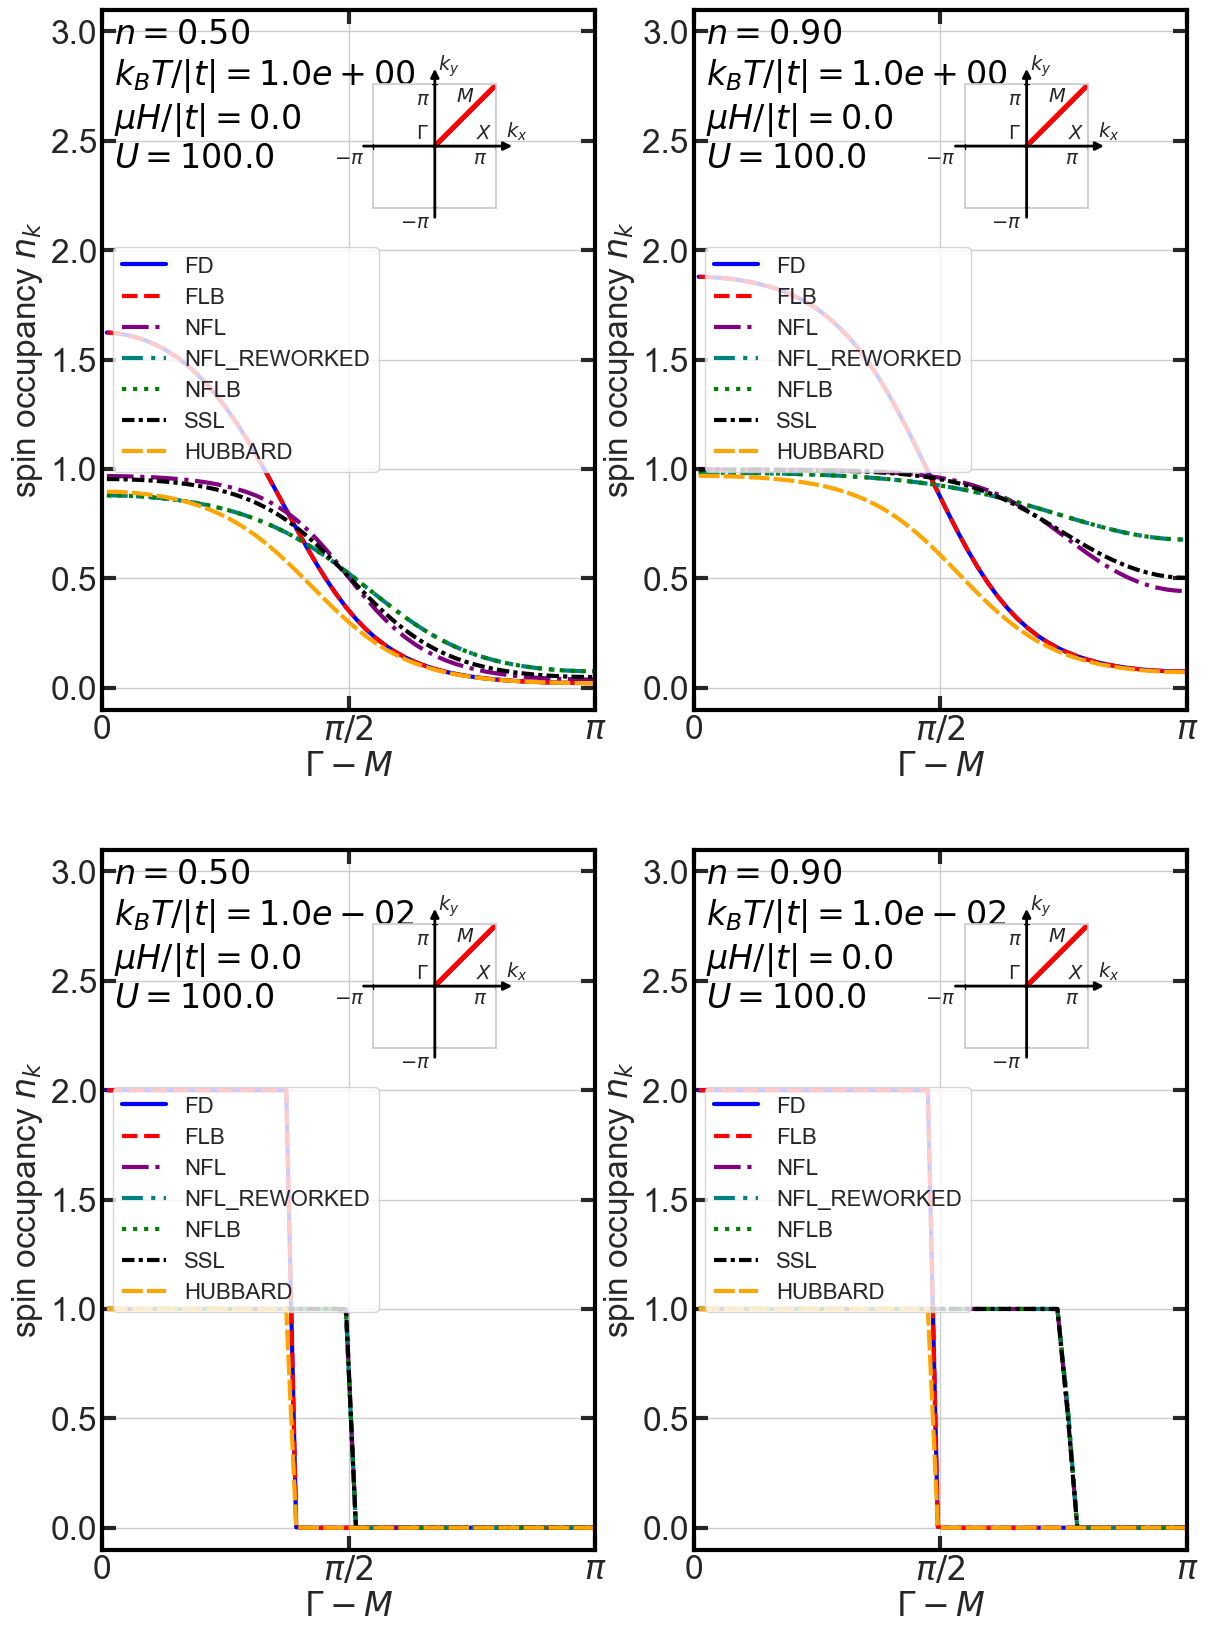

In [6]:
plotter.plot_energy_distribution_1d(
    e_k=e_k,
    slice_type="diagonal",
    dim=2,
    kx=kx,
    n=n_plot,
    kBTs=kBT_plot,
    H=H_a[0],
    U=U,
    distributions=distro_names,
    figsize=(14, 10),
    ylims=(-0.1, 3.1),
    bz_inset_pos=(0.55, 0.68, 0.25, 0.25),
)
plt.show()
